<a href="https://colab.research.google.com/github/RudhranB-07/GenAI-Rudhran-C4/blob/main/A1_Diabetes_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [44]:
data = pd.read_csv("/content/diabetes.csv")

In [45]:
data.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [46]:
data.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [47]:
data["Outcome"].value_counts()

,count
Outcome,
0,500
1,268


In [48]:
data.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


Glucose, Bp, Insulin, skin thickness and BMI can't be 0 in real world.

In [49]:
data['Glucose'] = data['Glucose'].replace(0,data[data['Glucose']!=0]['Glucose'].mean())

In [50]:
data['BloodPressure'] = data['BloodPressure'].replace(0,data[data['BloodPressure']!=0]['BloodPressure'].mean())
data['SkinThickness'] = data['SkinThickness'].replace(0,data[data['SkinThickness']!=0]['SkinThickness'].mean())
data['BMI'] = data['BMI'].replace(0,data[data['BMI']!=0]['BMI'].mean())

#using median for Insulin, because the 75% mark is  ~4 times smaller than the max value. can give false picture here.
data['Insulin'] = data['Insulin'].replace(0,data[data['Insulin']!=0]['Insulin'].median())

In [51]:
data.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,121.686763,72.405184,29.153420,140.671875,32.457464,0.471876,33.240885,0.348958
std,3.369578,30.435949,12.096346,8.790942,86.383060,6.875151,0.331329,11.760232,0.476951
min,0.000000,44.000000,24.000000,7.000000,14.000000,18.200000,0.078000,21.000000,0.000000
25%,1.000000,99.750000,64.000000,25.000000,121.500000,27.500000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.202592,29.153420,125.000000,32.400000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [52]:
# Bar graph
Diabetes=(data['Outcome']==1).sum()
No_Diabetes=(data['Outcome']==0).sum()
labels=['Diabetes','No Diabetes']
values=[Diabetes,No_Diabetes]

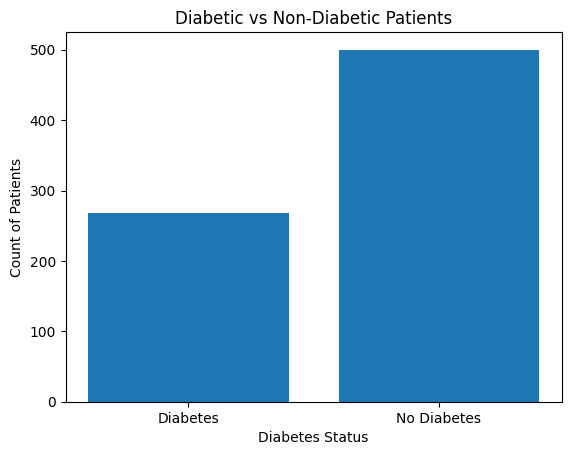

In [53]:
plt.bar(labels,values)
plt.xlabel('Diabetes Status')
plt.ylabel('Count of Patients')
plt.title('Diabetic vs Non-Diabetic Patients')
plt.show()

In [54]:
#Dividing data into dependednt and independent
x = data.drop(['Outcome'], axis=1)
y = data['Outcome']

In [55]:
#Splitting into test-train (training - 80%, testing - 20%)
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.20)

In [56]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression()

In [57]:
model.fit(x_train,y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [58]:
prediction = model.predict(x_test)

In [59]:
from sklearn.metrics import accuracy_score
accuracy_score = accuracy_score(y_test,prediction)

In [60]:
print(accuracy_score)

0.7922077922077922
